In [47]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [48]:
import sys
from pathlib import Path

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.append(str(root / "src"))

from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache(root / "cache" / "ddpg_td3_sac")

# Off-policy actor-critic: DDPG → TD3 → SAC

The environment is **Pendulum-v1**, which has a continuous action. Swing a pole up and hold it there.

- obs: `[cos θ, sin θ, θ̇]`
- action: one torque in `[-2, 2]`
- reward: `-(θ² + 0.1·θ̇² + 0.001·u²)`, so 0 is perfect (upright, still, no torque) and about -16 is the worst
- episodes never **terminate**, they only **truncate** at 200 steps


In [49]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
env = gym.wrappers.RecordEpisodeStatistics(
    gym.make("Pendulum-v1")
)  # info["episode"]["r"] at episode end
obs_dim = env.observation_space.shape[0]
act_dim = env.action_space.shape[0]
act_high = float(env.action_space.high[0])
print(f"{env.observation_space=}")
print(f"{env.action_space=}")
print(f"{obs_dim=}")
print(f"{act_dim=}")
print(f"{act_high=}")

env.observation_space=Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
env.action_space=Box(-2.0, 2.0, (1,), float32)
obs_dim=3
act_dim=1
act_high=2.0


In [50]:
scores = []
for _ in range(20):
    env.reset()
    done = False
    while not done:
        _, r, term, trunc, info = env.step(env.action_space.sample())
        done = term or trunc
    scores.append(info["episode"]["r"])
print(f"random baseline: {np.mean(scores):.0f}  (good agents get about -150)")

random baseline: -1366  (good agents get about -150)


## Why a new family?

**PPO is on-policy.** Each batch must come from the current policy, so after a few epochs it gets thrown away. That's stable but wasteful with samples.

**DQN is off-policy.** It keeps old transitions in a replay buffer and reuses each one many times. Its target needs `max_a Q(s', a)`, though. With 2 actions that's a lookup. With a continuous torque there are infinitely many actions, so you can't take the max.

**The fix (DDPG):** learn a second network, the actor `μ(s)`, that _outputs_ the argmax. You train it by gradient ascent on `Q(s, μ(s))`, nudging the action in the direction that makes Q bigger. Then `max_a Q(s', a) ≈ Q(s', μ(s'))`, and we're back to DQN-style learning from a replay buffer.

TD3 and SAC are fixes on top of that same skeleton.


## Step 1: the replay buffer

It stores transitions `(s, a, r, s', T)` and samples random minibatches. Two differences from PPO's batch:

- **No `logp`, no `D`.** Off-policy learning doesn't care which policy collected the data, and there's no GAE sum to stop at episode boundaries. Each transition stands alone.
- **Only `T` matters.** It zeroes the future value in the target `r + γ·(1-T)·Q(s', a')`. Pendulum never terminates, so `T` is always 0 here. A time-limit cut still bootstraps (same lesson as PPO).

It's a fixed-size circular array: once full, the newest transition overwrites the oldest.


In [51]:
class ReplayBuffer:
    def __init__(self, size=100_000):
        self.S = np.zeros((size, obs_dim), np.float32)
        self.A = np.zeros((size, act_dim), np.float32)
        self.R = np.zeros(size, np.float32)
        self.S2 = np.zeros((size, obs_dim), np.float32)
        self.T = np.zeros(size, np.float32)
        self.size, self.i, self.n = size, 0, 0  # i: next slot to write, n: slots filled

    def add(self, s, a, r, s2, term):
        self.S[self.i], self.A[self.i], self.R[self.i] = s, a, r
        self.S2[self.i], self.T[self.i] = s2, term
        self.i = (self.i + 1) % self.size  # wrap around: overwrite the oldest
        self.n = min(self.n + 1, self.size)

    def sample(self, batch_size=256):
        idx = np.random.randint(0, self.n, batch_size)
        f = lambda x: torch.as_tensor(x[idx], device=device)
        return dict(S=f(self.S), A=f(self.A), R=f(self.R), S2=f(self.S2), T=f(self.T))

In [52]:
buf = ReplayBuffer(size=500)  # tiny, to see the wrap-around
s, _ = env.reset(seed=0)
for _ in range(1200):  # 6 episodes, 2.4x the capacity
    a = env.action_space.sample()
    s2, r, term, trunc, _ = env.step(a)
    buf.add(s, a, r, s2, term)
    s = s2 if not (term or trunc) else env.reset()[0]

print("filled:", buf.n, " next write slot:", buf.i)  # 1200 % 500 = 200
b = buf.sample(4)
for k, v in b.items():
    print(f"{k:3s} {tuple(v.shape)}")
print("any terminal?", bool(buf.T.any()))  # Pendulum only truncates

filled: 500  next write slot: 200
S   (4, 3)
A   (4, 1)
R   (4,)
S2  (4, 3)
T   (4,)
any terminal? False


## Step 2: actor and critic

- **Actor** `μ(s)`: state → one action. It's deterministic: no distribution and no sampling, just `tanh` scaled to `[-2, 2]`. Exploration will come from noise added outside the network (Step 3).
- **Critic** `Q(s, a)`: the action is an **input**, concatenated with the state. DQN output one Q per action, which only works when you can list the actions.

This is the core trick: the critic is differentiable in `a`, so `∂Q/∂a` says which way to push the torque to get more value. The actor update is just "move `μ(s)` along `∂Q/∂a`", and backprop through `Q(s, μ(s))` does that for us.


In [53]:
def mlp(inp, out, hidden=256):
    return nn.Sequential(
        nn.Linear(inp, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden),
        nn.ReLU(), nn.Linear(hidden, out),
    ).to(device)


class Actor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim, act_dim)

    def forward(self, s):
        return act_high * torch.tanh(self.net(s))  # squash into the valid torque range


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim + act_dim, 1)  # action goes in, one Q comes out

    def forward(self, s, a):
        return self.net(torch.cat([s, a], -1)).squeeze(-1)

In [54]:
actor, critic = Actor(), Critic()
b = buf.sample(5)
a = actor(b["S"])
print("actions:", a.squeeze(1).tolist())
print("Q(s, a) shape:", tuple(critic(b["S"], a).shape))

# dQ/da: the direction the actor update will push each action
a = a.detach().requires_grad_()
critic(b["S"], a).sum().backward()
print("dQ/da:  ", a.grad.squeeze(1).tolist())

actions: [0.9391903877258301, 0.6109538078308105, 0.14741507172584534, 0.41627052426338196, 0.09859198331832886]
Q(s, a) shape: (5,)
dQ/da:   [-0.07091318815946579, -0.03864629566669464, -0.06953452527523041, -0.00479114567860961, -0.06237071007490158]


## Step 2b: target networks, soft updates

As in DQN, the TD target `r + γ·Q(s', μ(s'))` should come from slow-moving copies (`actor_t`, `critic_t`). Otherwise the label moves every time we fit it.

DQN hard-copied the weights every N steps. DDPG blends a little every step instead (Polyak averaging):

    θ_target ← (1 - τ)·θ_target + τ·θ,   τ = 0.005

The target trails the online net by about `1/τ = 200` updates, smoothly, with no jumps.


In [55]:
import copy


def soft_update(target, net, tau=0.005):
    with torch.no_grad():
        for tp, p in zip(target.parameters(), net.parameters()):
            tp.lerp_(p, tau)  # tp += tau * (p - tp)

In [56]:
critic_t = copy.deepcopy(critic)
with torch.no_grad():  # pretend training moved the online critic
    for p in critic.parameters():
        p.add_(torch.randn_like(p))

dist = lambda: (
    sum(
        (tp - p).pow(2).sum()
        for tp, p in zip(critic_t.parameters(), critic.parameters())
    )
    .sqrt()
    .item()
)
d0 = dist()
soft_update(critic_t, critic)
print(f"gap after 1 update:   {dist() / d0:.4f}  (expect 1 - tau = 0.995)")
for _ in range(199):
    soft_update(critic_t, critic)
print(
    f"gap after 200 updates: {dist() / d0:.4f}  (expect 0.995^200 = {0.995**200:.4f})"
)

gap after 1 update:   0.9950  (expect 1 - tau = 0.995)
gap after 200 updates: 0.3670  (expect 0.995^200 = 0.3670)


## Step 3: the DDPG update

One update on a sampled minibatch has two halves.

**Critic: DQN's regression, with the actor standing in for the max**

    y = r + γ·(1-T)·Q_t(s', μ_t(s'))        (both target nets, no gradient)
    critic_loss = (Q(s, a) - y)²

**Actor: climb the critic**

    actor_loss = -Q(s, μ(s))

The gradient flows through the critic into `μ`. We only step the actor's optimizer, so the critic is just a fixed judge here. (`backward` still leaves gradients on the critic's weights, but `opt_c.zero_grad()` clears them before the next critic step.)

Then both targets get a `soft_update`.

**Exploration:** the actor is deterministic, so `act` adds Gaussian noise (`0.1 × 2 = 0.2` torque std) when collecting data. That's fine off-policy: the buffer can hold data from any policy, noisy or not.


In [57]:
class DDPG:
    def __init__(self, lr=1e-3, gamma=0.99, tau=0.005, expl_noise=0.1):
        self.gamma, self.tau, self.expl_noise = gamma, tau, expl_noise
        self.actor, self.critic = Actor(), Critic()
        self.actor_t, self.critic_t = (
            copy.deepcopy(self.actor),
            copy.deepcopy(self.critic),
        )
        self.opt_a = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.opt_c = torch.optim.Adam(self.critic.parameters(), lr=lr)

    def act(self, s, explore=True):
        with torch.no_grad():
            a = (
                self.actor(torch.as_tensor(s, dtype=torch.float32, device=device))
                .cpu()
                .numpy()
            )
        if explore:
            a = a + np.random.normal(
                0, self.expl_noise * act_high, act_dim
            )  # the only exploration
        return np.clip(a, -act_high, act_high)

    def update(self, b):
        with torch.no_grad():
            q2 = self.critic_t(
                b["S2"], self.actor_t(b["S2"])
            )  # actor stands in for max_a
            y = b["R"] + self.gamma * (1 - b["T"]) * q2
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        actor_loss = -self.critic(
            b["S"], self.actor(b["S"])
        ).mean()  # push mu(s) up the Q surface
        self.opt_a.zero_grad()
        actor_loss.backward()
        self.opt_a.step()

        soft_update(self.actor_t, self.actor, self.tau)
        soft_update(self.critic_t, self.critic, self.tau)
        return dict(critic_loss=critic_loss.item(), q=q.mean().item())

In [58]:
agent = DDPG()
s, _ = env.reset(seed=0)
print(f"greedy: {agent.act(s, explore=False)[0]:+.3f}")
print("noisy: ", " ".join(f"{agent.act(s)[0]:+.3f}" for _ in range(4)))

# fit on the 500 random transitions already in buf, no new data
torch.manual_seed(0)
np.random.seed(0)
for i in range(1, 1001):
    b = buf.sample(256)
    stats = agent.update(b)
    if i % 200 == 0:
        with torch.no_grad():
            gain = agent.critic(b["S"], agent.actor(b["S"])) - agent.critic(
                b["S"], b["A"]
            )
        print(
            f"update {i:4d}  critic_loss={stats['critic_loss']:7.3f}  Q={stats['q']:7.2f}  "
            f"Q(s,mu(s)) - Q(s,a_random) = {gain.mean():+.2f}"
        )

greedy: +0.214
noisy:  +0.023 +0.374 -0.007 +0.395
update  200  critic_loss=  0.215  Q=  -9.84  Q(s,mu(s)) - Q(s,a_random) = +0.33
update  400  critic_loss=  0.093  Q= -14.50  Q(s,mu(s)) - Q(s,a_random) = +0.45
update  600  critic_loss=  0.066  Q= -18.36  Q(s,mu(s)) - Q(s,a_random) = +0.57
update  800  critic_loss=  0.082  Q= -24.22  Q(s,mu(s)) - Q(s,a_random) = +0.68
update 1000  critic_loss=  0.058  Q= -27.27  Q(s,mu(s)) - Q(s,a_random) = +0.78


## Step 4: the training loop

Unlike PPO's collect-batch-then-update, the off-policy loop interleaves: **one env step, then one gradient update**, every step.

- **Warm-up:** the first `start_steps` actions are uniformly random. This fills the buffer with diverse data before the critic means anything, and no updates happen yet.
- `buf.add(..., term)`: only a real termination zeroes the future. A time-limit cut (`trunc`) resets the env but still bootstraps.
- Each update samples a random minibatch from **everything collected so far**, so old transitions keep getting reused. That's where the sample efficiency comes from.

`algo` names the agent class, so TD3 and SAC can plug in later without editing this cell (which would invalidate the cache).


In [59]:
@cache
def train(
    algo="DDPG", total_steps=20_000, start_steps=1_000, batch_size=256, seed=0, **hp
):
    torch.manual_seed(seed)
    np.random.seed(seed)
    env = gym.wrappers.RecordEpisodeStatistics(gym.make("Pendulum-v1"))
    env.action_space.seed(seed)
    agent = globals()[algo](**hp)  # class by name: DDPG now, TD3/SAC later
    buf = ReplayBuffer()

    s, _ = env.reset(seed=seed)
    returns, ends, log, recent = (
        [],
        [],
        [],
        [],
    )  # ends[i]: env step at which episode i finished
    for step in range(1, total_steps + 1):
        a = env.action_space.sample() if step <= start_steps else agent.act(s)
        s2, r, term, trunc, info = env.step(a)
        buf.add(
            s, a, r, s2, term
        )  # trunc still bootstraps: only term zeroes the future
        s = s2
        if term or trunc:
            returns.append(float(info["episode"]["r"]))
            ends.append(step)
            s, _ = env.reset()

        if step > start_steps:
            recent.append(agent.update(buf.sample(batch_size)))
        if step % 2000 == 0 and recent:
            stats = {k: np.mean([st[k] for st in recent]) for k in recent[0]}
            log.append(dict(step=step, **stats))
            recent = []
            print(
                f"steps {step:6d}  episodes {len(returns):3d}  avg10={np.mean(returns[-10:]):7.1f}  "
                + "  ".join(f"{k}={v:.3f}" for k, v in stats.items())
            )

    return dict(agent=agent, returns=returns, ends=ends, log=log)

train: cached, 1 call(s) stored


In [60]:
res_ddpg = train("DDPG")

steps   2000  episodes  10  avg10=-1343.4  critic_loss=0.654  q=-18.733
steps   4000  episodes  20  avg10= -726.3  critic_loss=0.152  q=-54.604
steps   6000  episodes  30  avg10= -126.6  critic_loss=0.519  q=-65.910
steps   8000  episodes  40  avg10= -122.2  critic_loss=1.058  q=-60.829
steps  10000  episodes  50  avg10= -186.1  critic_loss=1.532  q=-53.568
steps  12000  episodes  60  avg10= -124.2  critic_loss=1.456  q=-45.674
steps  14000  episodes  70  avg10= -166.6  critic_loss=1.328  q=-38.795
steps  16000  episodes  80  avg10= -171.9  critic_loss=1.152  q=-33.793
steps  18000  episodes  90  avg10= -143.8  critic_loss=1.029  q=-30.079
steps  20000  episodes 100  avg10= -205.1  critic_loss=0.978  q=-27.440


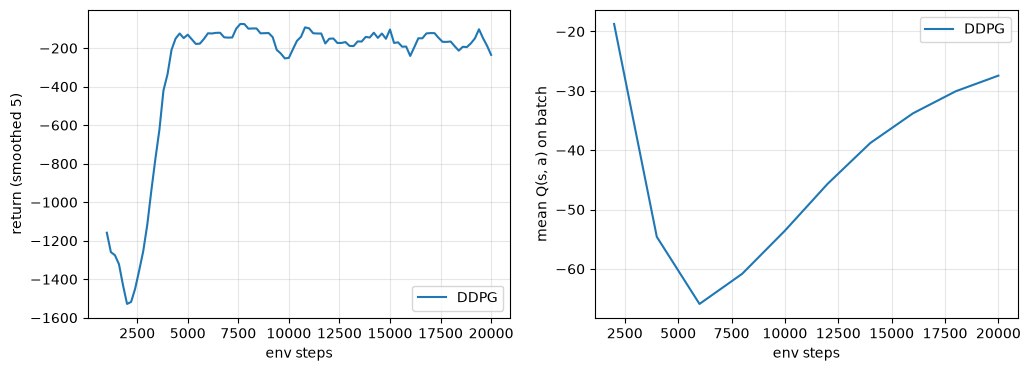

In [61]:
import matplotlib.pyplot as plt


def smooth(xs, k=5):
    return np.convolve(xs, np.ones(k) / k, mode="valid")


def plot_runs(runs, k=5):
    """runs: {label: train() result}. Return vs env steps, and the critic's mean Q."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for label, res in runs.items():
        ax1.plot(res["ends"][k - 1 :], smooth(res["returns"], k), label=label)
        ax2.plot(
            [l["step"] for l in res["log"]], [l["q"] for l in res["log"]], label=label
        )
    ax1.set_xlabel("env steps")
    ax1.set_ylabel(f"return (smoothed {k})")
    ax2.set_xlabel("env steps")
    ax2.set_ylabel("mean Q(s, a) on batch")
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.legend()
    plt.show()


plot_runs({"DDPG": res_ddpg})

In [62]:
def evaluate(agent, n_episodes=10, seed=100):
    """Greedy (no noise) returns."""
    env = gym.wrappers.RecordEpisodeStatistics(gym.make("Pendulum-v1"))
    scores = []
    for i in range(n_episodes):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, _, term, trunc, info = env.step(agent.act(s, explore=False))
            done = term or trunc
        scores.append(float(info["episode"]["r"]))
    return np.mean(scores), np.std(scores)


m, sd = evaluate(res_ddpg["agent"])
print(f"DDPG greedy: {m:.0f} ± {sd:.0f}   (random: about -1200)")

DDPG greedy: -165 ± 65   (random: about -1200)


In [63]:
vis = gym.make("Pendulum-v1", render_mode="human")
s, _ = vis.reset(seed=0)
total, done = 0.0, False
while not done:
    a = res_ddpg["agent"].act(
        s, explore=False
    )  # greedy; explore=True adds the training noise
    s, r, term, trunc, _ = vis.step(a)
    total += r
    done = term or trunc
vis.close()
print("DDPG episode reward:", total)

DDPG episode reward: -130.11661157026242


## Step 5: is DDPG's critic honest?

DDPG trains well on Pendulum, but is its critic _right_? We can check, because we know what Q should be: run the greedy policy, add up the discounted rewards it actually collects from each state (`G_t`), and compare with the critic's `Q(s_t, a_t)`.

- `Q > G`: the critic **overestimates**, it thinks things are better than they are.
- Only the first 100 steps of each episode count. Later steps lose too much of their future to the 200-step cutoff, so their `G_t` would be artificially low.


In [64]:
def q_bias(agent, n_episodes=5, gamma=0.99, horizon=100, seed=200):
    """Critic's Q(s_t, a_t) vs the discounted return actually received from s_t, on greedy episodes.
    Only the first `horizon` steps: later ones lose too much of their future to the 200-step cut."""
    env = gym.make("Pendulum-v1")
    qs, Gs = [], []
    for i in range(n_episodes):
        s, _ = env.reset(seed=seed + i)
        S, A, R, done = [], [], [], False
        while not done:
            a = agent.act(s, explore=False)
            S.append(s)
            A.append(a)
            s, r, term, trunc, _ = env.step(a)
            R.append(r)
            done = term or trunc
        G, ret = 0.0, []
        for r in reversed(R):
            G = r + gamma * G
            ret.append(G)
        Gs += list(reversed(ret))[:horizon]
        with torch.no_grad():
            f = lambda x: torch.as_tensor(
                np.array(x[:horizon]), dtype=torch.float32, device=device
            )
            qs += agent.critic(f(S), f(A)).tolist()
    return np.mean(qs), np.mean(Gs)

In [65]:
q, g = q_bias(res_ddpg["agent"])
print(f"DDPG  critic Q = {q:.1f}   actual G = {g:.1f}   bias = {q - g:+.1f}")

DDPG  critic Q = -17.0   actual G = -26.9   bias = +9.9


Q is too high by about 10. I checked 3 seeds, and all were +9.8 to +9.9, so this is systematic, not noise. Where does it come from?

**The actor hunts for the critic's mistakes.** The critic is a noisy fit. For some actions it's too high, for some too low. The actor's whole job is to find the action with the **highest** Q, so it lands on the spots where the critic is _too high_. That's DQN's `max` overestimation in a new form.

**Bootstrapping compounds it.** The inflated `Q(s', μ(s'))` goes into the target `y`, so the critic learns to be inflated one step earlier, and so on back.

On Pendulum the policy still works. On harder tasks the actor keeps chasing phantom value and training falls apart. That's what TD3 fixes.


## Step 6: TD3 (Twin Delayed DDPG)

Three changes to `DDPG.update`. Everything else (buffer, act, loop) stays the same, so `TD3` just subclasses `DDPG`.

1. **Twin critics: trust the pessimist.** Train two independent critics on the same target and build the target from the **min** of their two estimates. An action that one critic overrates is unlikely to be overrated by both, so the min cancels most of the upward bias. (Same idea as Double DQN.)
2. **Delayed actor updates.** Update the actor and the target networks only every 2nd critic update. A half-fitted critic gives garbage gradients, so let it settle before the actor follows it.
3. **Target smoothing.** Add small clipped noise to `μ_t(s')` in the target. Similar actions should have similar values, so the critic can't create a narrow, spiky peak for the actor to exploit.

The actor still climbs only `critic` (the first one). `critic2` exists only to keep the target honest.


In [66]:
class TD3(DDPG):
    def __init__(self, lr=1e-3, policy_delay=2, target_noise=0.2, noise_clip=0.5, **kw):
        super().__init__(lr=lr, **kw)
        self.policy_delay, self.target_noise, self.noise_clip = (
            policy_delay,
            target_noise,
            noise_clip,
        )
        self.critic2 = Critic()
        self.critic2_t = copy.deepcopy(self.critic2)
        self.opt_c = torch.optim.Adam(
            [*self.critic.parameters(), *self.critic2.parameters()], lr=lr
        )
        self.n_updates = 0

    def update(self, b):
        with torch.no_grad():
            # fix 3: smooth the target, jitter mu_t(s') so Q can't rely on one sharp peak
            noise = (torch.randn_like(b["A"]) * self.target_noise * act_high).clamp(
                -self.noise_clip * act_high, self.noise_clip * act_high
            )
            a2 = (self.actor_t(b["S2"]) + noise).clamp(-act_high, act_high)
            # fix 1: two critics, trust the smaller target
            q2 = torch.min(self.critic_t(b["S2"], a2), self.critic2_t(b["S2"], a2))
            y = b["R"] + self.gamma * (1 - b["T"]) * q2
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y) + F.mse_loss(self.critic2(b["S"], b["A"]), y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        # fix 2: update the actor (and all targets) only every policy_delay critic updates
        self.n_updates += 1
        if self.n_updates % self.policy_delay == 0:
            actor_loss = -self.critic(b["S"], self.actor(b["S"])).mean()
            self.opt_a.zero_grad()
            actor_loss.backward()
            self.opt_a.step()
            soft_update(self.actor_t, self.actor, self.tau)
            soft_update(self.critic_t, self.critic, self.tau)
            soft_update(self.critic2_t, self.critic2, self.tau)
        return dict(critic_loss=critic_loss.item(), q=q.mean().item())

In [67]:
res_td3 = train("TD3")

steps   2000  episodes  10  avg10=-1345.0  critic_loss=1.265  q=-12.627
steps   4000  episodes  20  avg10=-1292.0  critic_loss=0.092  q=-34.246
steps   6000  episodes  30  avg10= -667.2  critic_loss=0.286  q=-57.611
steps   8000  episodes  40  avg10= -134.6  critic_loss=0.551  q=-64.673
steps  10000  episodes  50  avg10= -202.4  critic_loss=0.991  q=-64.463
steps  12000  episodes  60  avg10= -134.9  critic_loss=1.512  q=-62.671
steps  14000  episodes  70  avg10= -180.6  critic_loss=2.329  q=-61.104
steps  16000  episodes  80  avg10= -183.9  critic_loss=3.244  q=-59.671
steps  18000  episodes  90  avg10= -141.5  critic_loss=3.796  q=-57.474
steps  20000  episodes 100  avg10= -202.8  critic_loss=3.837  q=-54.780


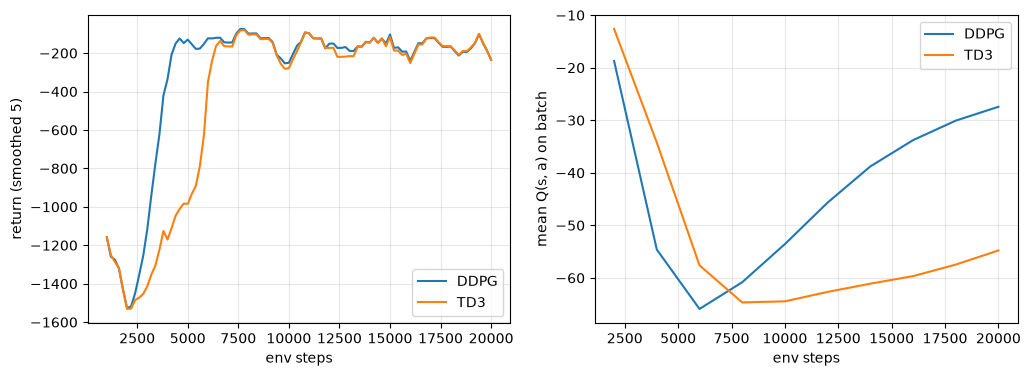

DDPG  greedy  -165 ±  65   critic Q =  -17.0   actual G =  -26.9   bias = +9.9
TD3   greedy  -164 ±  68   critic Q =  -22.9   actual G =  -23.6   bias = +0.7


In [68]:
plot_runs({"DDPG": res_ddpg, "TD3": res_td3})
for name, res in [("DDPG", res_ddpg), ("TD3", res_td3)]:
    m, sd = evaluate(res["agent"])
    q, g = q_bias(res["agent"])
    print(
        f"{name:5s} greedy {m:5.0f} ± {sd:3.0f}   critic Q = {q:6.1f}   actual G = {g:6.1f}   bias = {q - g:+.1f}"
    )

**Same return, honest critic.** Over 3 seeds, both reach about -165, but DDPG's bias stays near +10 while TD3's is under +1. Pendulum is too easy for DDPG's inflated values to hurt it. On harder tasks (MuJoCo walkers) that same bias is exactly what makes DDPG unstable, and TD3 clearly outperforms it.

TD3's Q curve on the right sits lower than DDPG's: that's the min of two critics at work, not worse learning.


## Step 7: SAC's stochastic actor

DDPG and TD3 have a deterministic actor and explore by adding noise from outside the network. SAC (Soft Actor-Critic) makes the actor **output a distribution**, like PPO's policy but for a continuous action:

- The net outputs a mean `μ` and a log-std for each action dimension.
- Sample `u ~ Normal(μ, σ)`, then squash: `a = 2·tanh(u)`, so it's always a valid torque.
- Exploration is now part of the policy. The network itself decides how random to be in each state.

SAC needs two technical pieces:

**1. `rsample` (the reparameterization trick).** The actor loss will backprop through `Q(s, a)` into the sampled action, as in DDPG. A plain `sample()` cuts the gradient. `rsample()` computes `u = μ + σ·ε` with `ε ~ Normal(0, 1)`, so `u` is a differentiable function of `μ` and `σ`.

**2. The tanh correction to the log-prob.** SAC needs `log π(a|s)`, and the Normal gives `log p(u)`. `tanh` squeezes the real line into `[-1, 1]`, piling up density near the edges, so the log-prob must be corrected by `-log(1 - tanh(u)²)` (change of variables). The code uses an algebraically equal form that doesn't blow up when `tanh(u) ≈ ±1`.

`deterministic=True` returns `2·tanh(μ)`, the most likely action. It's used for evaluation.


In [ ]:
class GaussianActor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim, 2 * act_dim)  # mean and log-std per action dim

    def forward(self, s, deterministic=False):
        """Returns (action in [-2, 2], log-prob of that action)."""
        mu, log_std = self.net(s).chunk(2, -1)
        log_std = log_std.clamp(-20, 2)  # keep std in a sane range
        dist = torch.distributions.Normal(mu, log_std.exp())
        u = (
            mu if deterministic else dist.rsample()
        )  # rsample: the sample stays differentiable
        a = torch.tanh(u)  # squash into [-1, 1]
        # change of variables: tanh squeezes density near +-1, so correct by log(1 - tanh(u)^2),
        # written in a numerically stable form
        logp = dist.log_prob(u).sum(-1) - (
            2 * (np.log(2) - u - F.softplus(-2 * u))
        ).sum(-1)
        return act_high * a, logp

In [70]:
actor = GaussianActor()
s = torch.as_tensor(env.reset(seed=0)[0], device=device).repeat(
    5, 1
)  # the same state 5 times
a, logp = actor(s)
print("5 samples, one state:", " ".join(f"{x:+.3f}" for x in a.squeeze(1).tolist()))
print("deterministic:       ", f"{actor(s[:1], deterministic=True)[0].item():+.3f}")

# check the tanh correction against torch's built-in squashed distribution
mu, log_std = actor.net(s).chunk(2, -1)
ref = torch.distributions.TransformedDistribution(
    torch.distributions.Normal(mu, log_std.clamp(-20, 2).exp()),
    [torch.distributions.TanhTransform()],
)
print(
    "logp matches torch:",
    torch.allclose(logp, ref.log_prob(a / act_high).sum(-1), atol=1e-3),
)

5 samples, one state: +1.229 +0.382 +0.024 -1.587 +1.733
deterministic:        -0.116
logp matches torch: True


In [74]:
logp

tensor([-0.7414, -0.9064, -0.9139, -0.4496, -0.4840], device='cuda:0',
       grad_fn=<SubBackward0>)

## Step 8: the SAC update

SAC changes the goal: maximize reward **plus** `α × entropy`. The agent gets paid for staying random, so it keeps exploring and won't collapse onto one sharp action the critic happens to overrate.

That bonus `-α·log π` shows up in two places:

**Critic target (a "soft" Q):**

    a' ~ π(·|s')                                          (fresh sample, current actor)
    y  = r + γ·(1-T)·( min(Q1_t, Q2_t)(s', a')  -  α·log π(a'|s') )

**Actor:** high Q, but not at the cost of all randomness:

    a ~ π(·|s)   (rsample)
    actor_loss = α·log π(a|s) - min(Q1, Q2)(s, a)

**Auto-tuning α.** Picking α by hand is fiddly, because the right value depends on the reward scale. Instead, set a target entropy (`-act_dim`, the standard choice) and learn α. If the policy is less random than the target, α goes up; if more random, α goes down. Early on, high α means broad exploration. As the critic gets confident, α shrinks and the policy sharpens.

**Compared with TD3:**

- It keeps the twin critics and the min, for the same overestimation reason.
- It drops the target actor and the delayed actor updates. Target smoothing isn't needed either, because sampling `a'` from a stochastic policy already blurs the target.


In [71]:
class SAC:
    def __init__(self, lr=1e-3, gamma=0.99, tau=0.005, alpha=None):
        self.gamma, self.tau = gamma, tau
        self.actor = GaussianActor()
        self.critic, self.critic2 = Critic(), Critic()
        self.critic_t, self.critic2_t = (
            copy.deepcopy(self.critic),
            copy.deepcopy(self.critic2),
        )
        self.opt_a = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.opt_c = torch.optim.Adam(
            [*self.critic.parameters(), *self.critic2.parameters()], lr=lr
        )
        # alpha=None: learn it. Learn log(alpha) so alpha stays positive; start at alpha = 1
        self.auto_alpha = alpha is None
        self.log_alpha = torch.tensor(
            float(np.log(alpha or 1.0)), device=device, requires_grad=self.auto_alpha
        )
        self.opt_alpha = torch.optim.Adam([self.log_alpha], lr=lr)
        self.target_entropy = (
            -act_dim
        )  # how random to stay: about std 0.09 in [-1, 1] units

    def act(self, s, explore=True):
        with torch.no_grad():
            a, _ = self.actor(
                torch.as_tensor(s, dtype=torch.float32, device=device),
                deterministic=not explore,
            )
        return a.cpu().numpy()  # exploration comes from sampling, no added noise

    def update(self, b):
        alpha = self.log_alpha.exp().item()
        with torch.no_grad():
            a2, logp2 = self.actor(
                b["S2"]
            )  # fresh sample from the current policy, no target actor
            q2 = torch.min(self.critic_t(b["S2"], a2), self.critic2_t(b["S2"], a2))
            y = b["R"] + self.gamma * (1 - b["T"]) * (
                q2 - alpha * logp2
            )  # + bonus for being random
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y) + F.mse_loss(self.critic2(b["S"], b["A"]), y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        a, logp = self.actor(b["S"])  # gradient flows through the sampled a (rsample)
        q_pi = torch.min(self.critic(b["S"], a), self.critic2(b["S"], a))
        actor_loss = (alpha * logp - q_pi).mean()  # high Q, but stay random
        self.opt_a.zero_grad()
        actor_loss.backward()
        self.opt_a.step()

        if self.auto_alpha:
            # entropy below target -> raise alpha (reward randomness more), above -> lower it
            alpha_loss = -(
                self.log_alpha * (logp.detach() + self.target_entropy)
            ).mean()
            self.opt_alpha.zero_grad()
            alpha_loss.backward()
            self.opt_alpha.step()

        soft_update(self.critic_t, self.critic, self.tau)
        soft_update(self.critic2_t, self.critic2, self.tau)
        return dict(
            critic_loss=critic_loss.item(),
            q=q.mean().item(),
            alpha=alpha,
            entropy=-logp.mean().item(),
        )

In [72]:
res_sac = train("SAC")

steps   2000  episodes  10  avg10=-1338.4  critic_loss=1.314  q=-17.904  alpha=0.636  entropy=0.529
steps   4000  episodes  20  avg10= -777.9  critic_loss=0.297  q=-55.586  alpha=0.242  entropy=-0.598
steps   6000  episodes  30  avg10= -125.4  critic_loss=0.942  q=-69.330  alpha=0.170  entropy=-0.908
steps   8000  episodes  40  avg10= -122.1  critic_loss=1.791  q=-66.625  alpha=0.087  entropy=-0.947
steps  10000  episodes  50  avg10= -188.0  critic_loss=2.306  q=-60.687  alpha=0.068  entropy=-0.991
steps  12000  episodes  60  avg10= -125.1  critic_loss=2.169  q=-54.117  alpha=0.054  entropy=-0.974
steps  14000  episodes  70  avg10= -166.7  critic_loss=1.921  q=-47.649  alpha=0.042  entropy=-0.997
steps  16000  episodes  80  avg10= -171.6  critic_loss=1.781  q=-42.878  alpha=0.036  entropy=-0.975
steps  18000  episodes  90  avg10= -141.5  critic_loss=1.725  q=-39.367  alpha=0.026  entropy=-0.988
steps  20000  episodes 100  avg10= -190.4  critic_loss=1.787  q=-36.875  alpha=0.023  entrop

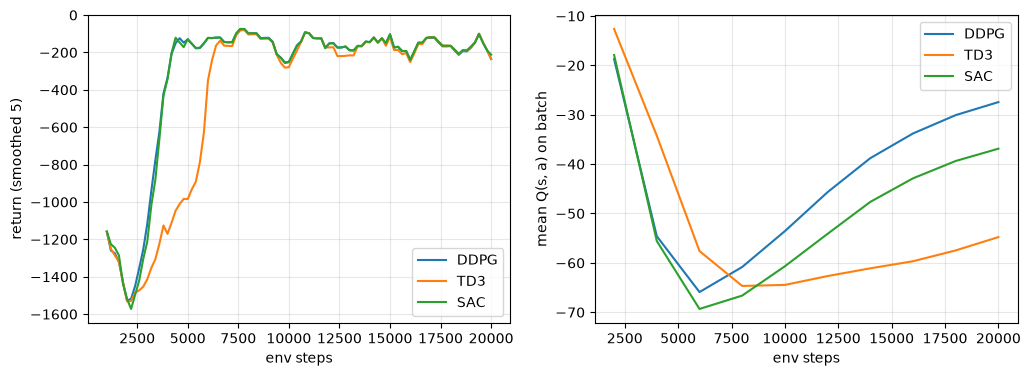

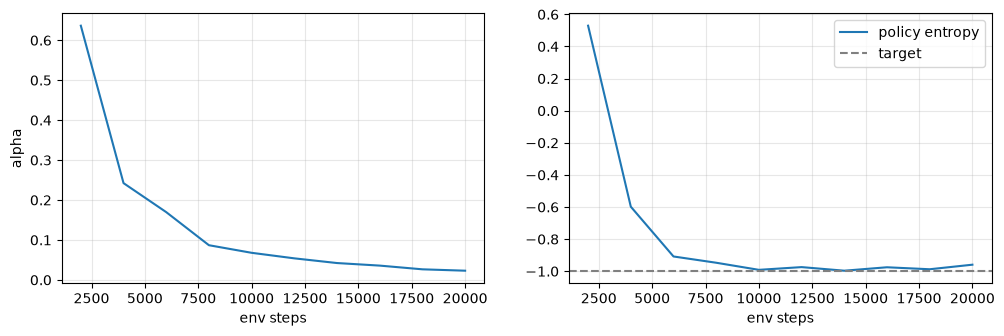

DDPG  greedy  -165 ±  65
TD3   greedy  -164 ±  68
SAC   greedy  -164 ±  67


In [73]:
plot_runs({"DDPG": res_ddpg, "TD3": res_td3, "SAC": res_sac})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
steps = [l["step"] for l in res_sac["log"]]
ax1.plot(steps, [l["alpha"] for l in res_sac["log"]])
ax1.set_ylabel("alpha")
ax2.plot(steps, [l["entropy"] for l in res_sac["log"]], label="policy entropy")
ax2.axhline(-act_dim, color="gray", linestyle="--", label="target")
ax2.legend()
for ax in (ax1, ax2):
    ax.set_xlabel("env steps")
    ax.grid(alpha=0.3)
plt.show()

for name, res in [("DDPG", res_ddpg), ("TD3", res_td3), ("SAC", res_sac)]:
    m, sd = evaluate(res["agent"])
    print(f"{name:5s} greedy {m:5.0f} ± {sd:3.0f}")

**All three solve Pendulum** at about -165, and SAC learns as fast as the others. Watch the bottom plots: α starts at 1 (lots of randomness rewarded) and decays toward 0.02–0.04 as entropy settles on the target. That's the policy sharpening by itself, with no noise schedule.

SAC's Q isn't comparable with `q_bias`: its critic learns the **soft** Q, which includes the future entropy bonus.

Pendulum is too easy to separate the three. On harder continuous control, SAC and TD3 both clearly beat DDPG, and SAC is generally the most robust to hyperparameters. That's why it's the default off-policy baseline.
